<a href="https://colab.research.google.com/github/sharonpramod27/Adult_Income/blob/main/Adult_Income.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder, OrdinalEncoder
from imblearn.over_sampling import SMOTE

In [2]:
filepath = '/content/adult_dataset.csv'
df = pd.read_csv(filepath, na_values='?', skipinitialspace=True)

In [3]:
df.head(10)

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39.0,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40.0,NaN,<=50K
1,50.0,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13.0,United-States,<=50K
2,38.0,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States,<=50K
3,53.0,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States,<=50K
4,28.0,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba,<=50K
5,37.0,Private,284582,Masters,14,Married-civ-spouse,Exec-managerial,Wife,White,Female,0,0,40.0,United-States,<=50K
6,49.0,Private,160187,9th,5,Married-spouse-absent,Other-service,Not-in-family,Black,Female,0,0,16.0,Jamaica,<=50K
7,52.0,Self-emp-not-inc,209642,HS-grad,9,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,45.0,United-States,>50K
8,31.0,Private,45781,Masters,14,Never-married,Prof-specialty,Not-in-family,White,Female,14084,0,50.0,United-States,>50K
9,42.0,Private,159449,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,5178,0,40.0,United-States,>50K


In [4]:
pd.set_option("display.max_columns", None)
df.tail()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
48837,39.0,Private,215419,Bachelors,13,Divorced,Prof-specialty,Not-in-family,White,Female,0,0,36.0,United-States,<=50K.
48838,64.0,NaN,321403,HS-grad,9,Widowed,NaN,Other-relative,Black,Male,0,0,40.0,United-States,<=50K.
48839,38.0,Private,374983,Bachelors,13,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,50.0,United-States,<=50K.
48840,44.0,Private,83891,Bachelors,13,Divorced,Adm-clerical,Own-child,Asian-Pac-Islander,Male,5455,0,40.0,United-States,<=50K.
48841,35.0,Self-emp-inc,182148,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,60.0,United-States,>50K.


In [5]:
df.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,46400.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,46400.000000
mean,38.679116,1.896641e+05,10.078089,1079.067626,87.502314,40.448599
std,13.952954,1.056040e+05,2.570973,7452.019058,403.004552,12.646992
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,255.000000,1.490400e+06,16.000000,99999.000000,4356.000000,250.000000


In [6]:
df.shape

(48842, 15)

In [7]:
target_col = "income"
df[target_col].value_counts()

,count
income,
<=50K,24720
<=50K.,12435
>50K,7841
>50K.,3846


In [8]:
X = df.drop(target_col, axis=1)
y = df[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [9]:
numerical_cols = X_train.select_dtypes(include="number").columns
categorical_cols = X_train.select_dtypes(include=["object"]).columns

In [10]:
num_imputer = SimpleImputer(strategy="median")
X_train_num = num_imputer.fit_transform(X_train[numerical_cols])
X_test_num = num_imputer.transform(X_test[numerical_cols])

In [11]:
cat_imputer = SimpleImputer(strategy="most_frequent")
X_train_cat = cat_imputer.fit_transform(X_train[categorical_cols])
X_test_cat = cat_imputer.transform(X_test[categorical_cols])

In [12]:
encoder = OneHotEncoder()
encoded_data = encoder.fit_transform(df[["workclass"]].fillna("Missing"))
encoded_df = pd.DataFrame(
    encoded_data.toarray(),
    columns=encoder.get_feature_names_out(["workclass"]),
    index=df.index
)

df_encoded = pd.concat([df.drop(["fnlwgt"], axis=1, errors='ignore'), encoded_df], axis=1)
pd.get_dummies(df_encoded, columns=None, drop_first=False, dtype=int)

,age,education-num,capital-gain,capital-loss,hours-per-week,workclass_Federal-gov,workclass_Local-gov,workclass_Missing,workclass_Never-worked,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,workclass_State-gov,workclass_Without-pay,workclass_Federal-gov,workclass_Local-gov,workclass_Never-worked,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,workclass_State-gov,workclass_Without-pay,education_10th,education_11th,education_12th,education_1st-4th,education_5th-6th,education_7th-8th,education_9th,education_Assoc-acdm,education_Assoc-voc,education_Bachelors,education_Doctorate,education_HS-grad,education_Masters,education_Preschool,education_Prof-school,education_Some-college,marital-status_Divorced,marital-status_Married-AF-spouse,marital-status_Married-civ-spouse,marital-status_Married-spouse-absent,marital-status_Never-married,marital-status_Separated,marital-status_Widowed,occupation_Adm-clerical,occupation_Armed-Forces,occupation_Craft-repair,occupation_Exec-managerial,occupation_Farming-fishing,occupation_Handlers-cleaners,occupation_Machine-op-inspct,occupation_Other-service,occupation_Priv-house-serv,occupation_Prof-specialty,occupation_Protective-serv,occupation_Sales,occupation_Tech-support,occupation_Transport-moving,relationship_Husband,relationship_Not-in-family,relationship_Other-relative,relationship_Own-child,relationship_Unmarried,relationship_Wife,race_Amer-Indian-Eskimo,race_Asian-Pac-Islander,race_Black,race_Other,race_White,sex_Female,sex_Male,native-country_Cambodia,native-country_Canada,native-country_China,native-country_Columbia,native-country_Cuba,native-country_Dominican-Republic,native-country_Ecuador,native-country_El-Salvador,native-country_England,native-country_France,native-country_Germany,native-country_Greece,native-country_Guatemala,native-country_Haiti,native-country_Holand-Netherlands,native-country_Honduras,native-country_Hong,native-country_Hungary,native-country_India,native-country_Iran,native-country_Ireland,native-country_Italy,native-country_Jamaica,native-country_Japan,native-country_Laos,native-country_Mexico,native-country_Nicaragua,native-country_Outlying-US(Guam-USVI-etc),native-country_Peru,native-country_Philippines,native-country_Poland,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia,income_<=50K,income_<=50K.,income_>50K,income_>50K.
0,39.0,13,2174,0,40.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
1,50.0,13,0,0,13.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0
2,38.0,9,0,0,40.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0
3,53.0,7,0,0,40.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0
4,28.0,13,0,0,40.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,.

In [13]:
clean_categorical_cols = [col for col in categorical_cols if col != 'fnlwgt']

X_train_cat_clean = pd.DataFrame(X_train_cat, columns=categorical_cols, index=X_train.index)[clean_categorical_cols]
X_test_cat_clean = pd.DataFrame(X_test_cat, columns=categorical_cols, index=X_test.index)[clean_categorical_cols]

ordinal_encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
X_train_ordinal = ordinal_encoder.fit_transform(X_train_cat_clean)
X_test_ordinal = ordinal_encoder.transform(X_test_cat_clean)

X_train_ordinal_df = pd.DataFrame(X_train_ordinal, columns=clean_categorical_cols, index=X_train.index)
X_train_ordinal_df.head()

,workclass,education,marital-status,occupation,relationship,race,sex,native-country
32369,3.0,11.0,4.0,2.0,1.0,4.0,1.0,38.0
4402,3.0,9.0,4.0,11.0,3.0,4.0,0.0,38.0
38451,4.0,9.0,2.0,4.0,0.0,4.0,1.0,38.0
17233,3.0,11.0,0.0,7.0,1.0,4.0,0.0,25.0
41292,5.0,15.0,2.0,9.0,0.0,4.0,1.0,38.0


In [14]:
X_train_num_df = pd.DataFrame(X_train_num, columns=numerical_cols, index=X_train.index)
X_test_num_df = pd.DataFrame(X_test_num, columns=numerical_cols, index=X_test.index)
X_test_ordinal_df = pd.DataFrame(X_test_ordinal, columns=clean_categorical_cols, index=X_test.index)

X_train_processed = pd.concat([X_train_num_df, X_train_ordinal_df], axis=1)
X_test_processed = pd.concat([X_test_num_df, X_test_ordinal_df], axis=1)

X_train_processed.head()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week,workclass,education,marital-status,occupation,relationship,race,sex,native-country
32369,22.0,174043.0,9.0,0.0,0.0,40.0,3.0,11.0,4.0,2.0,1.0,4.0,1.0,38.0
4402,24.0,399449.0,13.0,0.0,0.0,40.0,3.0,9.0,4.0,11.0,3.0,4.0,0.0,38.0
38451,44.0,79521.0,13.0,15024.0,0.0,55.0,4.0,9.0,2.0,4.0,0.0,4.0,1.0,38.0
17233,25.0,352806.0,9.0,0.0,0.0,40.0,3.0,11.0,0.0,7.0,1.0,4.0,0.0,25.0
41292,56.0,52822.0,10.0,0.0,0.0,40.0,5.0,15.0,2.0,9.0,0.0,4.0,1.0,38.0


In [15]:
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

print("Target Classes:", label_encoder.classes_)
print("Encoded y_train (first 10):", y_train_encoded[:10])

Target Classes: ['<=50K' '<=50K.' '>50K' '>50K.']
Encoded y_train (first 10): [0 0 3 0 1 0 3 0 1 0]


In [16]:
leakage_cols = ['education', 'fnlwgt']
X_train_clean = X_train_processed.drop(columns=leakage_cols, errors='ignore')
X_test_clean = X_test_processed.drop(columns=leakage_cols, errors='ignore')

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_clean)
X_test_scaled = scaler.transform(X_test_clean)

print("Clean training shape:", X_train_scaled.shape)

Clean training shape: (39073, 12)


In [17]:
unique_before, counts_before = np.unique(y_train_encoded, return_counts=True)
print("Before SMOTE:", dict(zip(label_encoder.inverse_transform(unique_before), counts_before)))

smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train_scaled, y_train_encoded)

unique_after, counts_after = np.unique(y_train_balanced, return_counts=True)
print("After SMOTE:", dict(zip(label_encoder.inverse_transform(unique_after), counts_after)))

Before SMOTE: {'<=50K': np.int64(19775), '<=50K.': np.int64(9948), '>50K': np.int64(6273), '>50K.': np.int64(3077)}
After SMOTE: {'<=50K': np.int64(19775), '<=50K.': np.int64(19775), '>50K': np.int64(19775), '>50K.': np.int64(19775)}


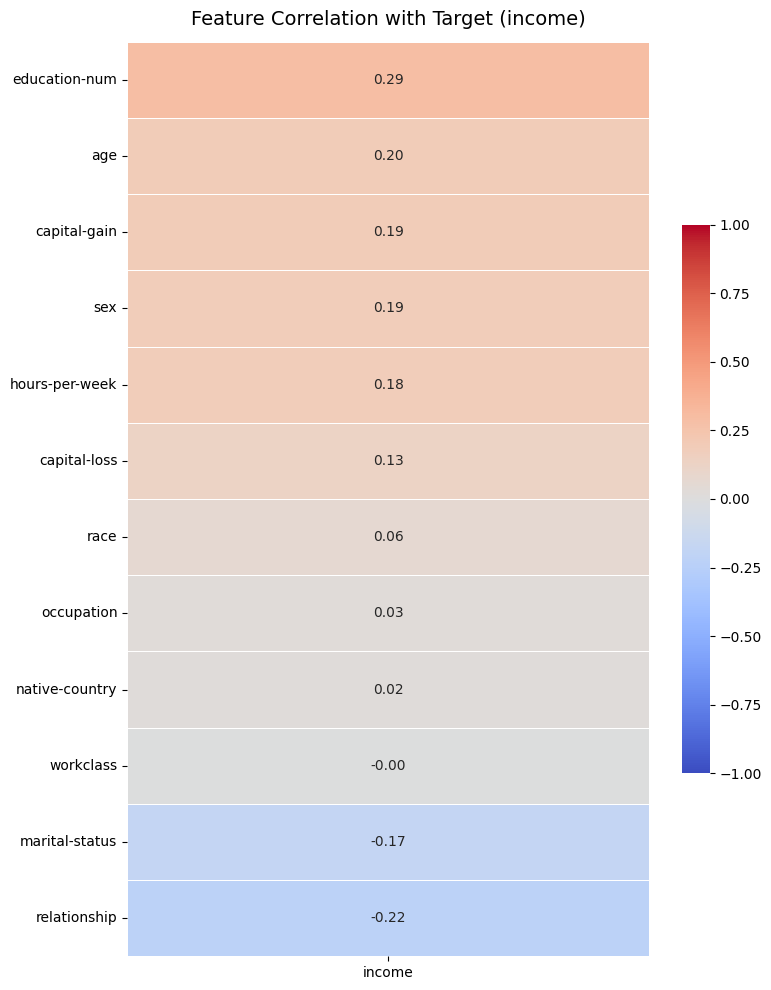

In [18]:
corr_with_target = X_train_clean.copy()
corr_with_target[target_col] = y_train_encoded

target_corr = corr_with_target.corr()[[target_col]].drop(target_col).sort_values(by=target_col, ascending=False)

plt.figure(figsize=(8, 10))
sns.heatmap(
    target_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    cbar_kws={"shrink": 0.6}
)
plt.title(f"Feature Correlation with Target ({target_col})", fontsize=14, pad=12)
plt.tight_layout()
plt.show()

In [19]:
features_selected = ["hours-per-week", "education-num", "marital-status"]

X_train_selected = X_train_clean[features_selected]
X_test_selected = X_test_clean[features_selected]

print("Selected training set shape:", X_train_selected.shape)
X_train_selected.head()

Selected training set shape: (39073, 3)


,hours-per-week,education-num,marital-status
32369,40.0,9.0,4.0
4402,40.0,13.0,4.0
38451,55.0,13.0,2.0
17233,40.0,9.0,0.0
41292,40.0,10.0,2.0


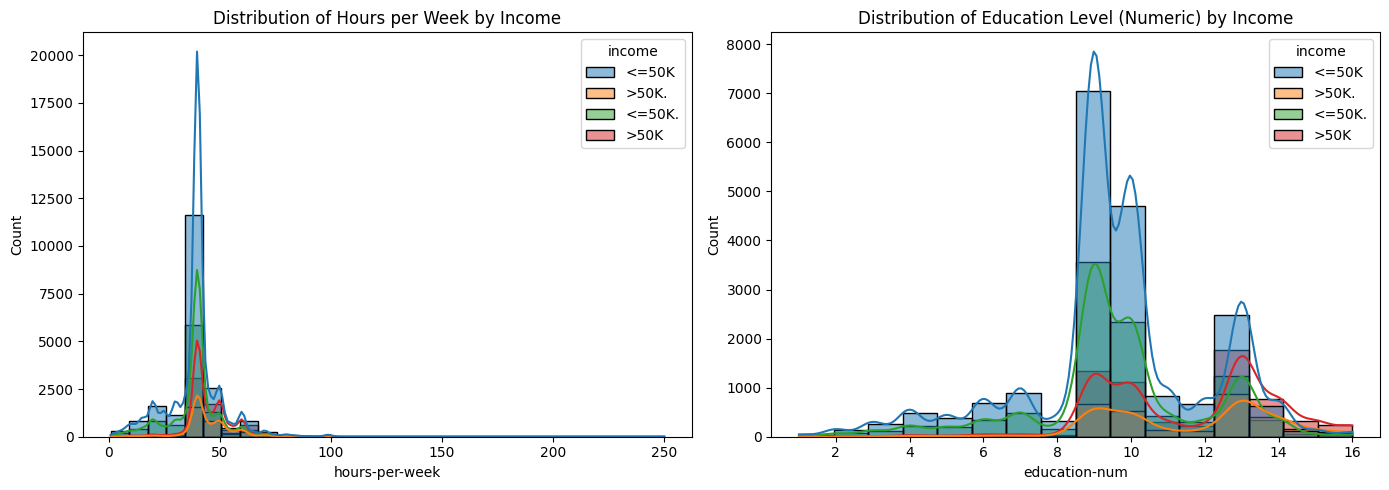

In [20]:
plot_df = X_train_selected.copy()
plot_df[target_col] = y_train

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=plot_df, x='hours-per-week', hue=target_col, kde=True, bins=30, ax=axes[0])
axes[0].set_title('Distribution of Hours per Week by Income')

sns.histplot(data=plot_df, x='education-num', hue=target_col, kde=True, bins=16, ax=axes[1])
axes[1].set_title('Distribution of Education Level (Numeric) by Income')

plt.tight_layout()
plt.show()

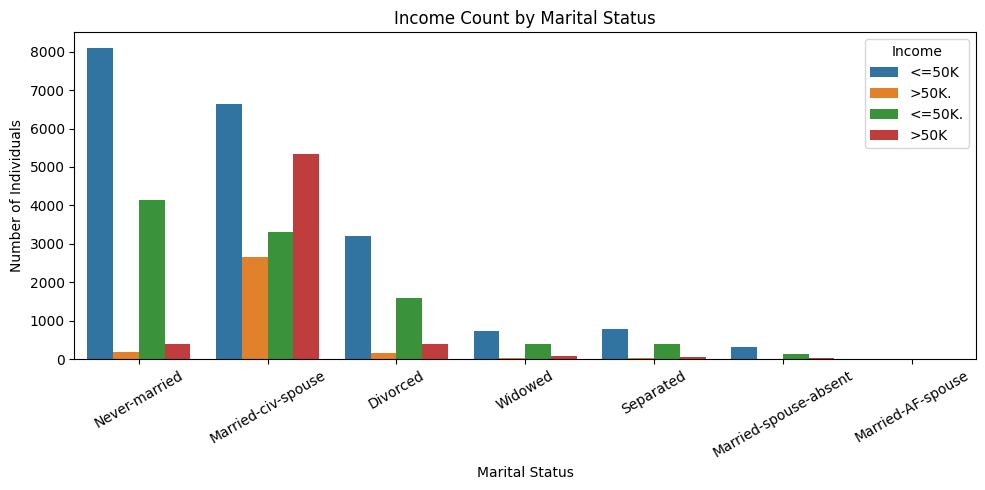

In [21]:
plt.figure(figsize=(10, 5))
sns.countplot(data=X_train, x='marital-status', hue=y_train)
plt.title('Income Count by Marital Status')
plt.xlabel('Marital Status')
plt.ylabel('Number of Individuals')
plt.xticks(rotation=30)
plt.legend(title='Income')
plt.tight_layout()
plt.show()